# 从零手撕 Policy Gradient：从查 Q 表，到直接学习动作概率

> 上一章让一张表学会评价动作；这一章让一个小网络直接学习“在这里，该以多大概率采取哪个动作”。

**学习主线：OpenAI Spinning Up。** 本笔记参考其 [核心概念](https://spinningup.openai.com/en/latest/spinningup/rl_intro.html)、[算法分类](https://spinningup.openai.com/en/latest/spinningup/rl_intro2.html) 与 [策略优化入门](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html)。这里的中文解释、手算、图示与实验代码为独立教学实现，不是官方文档翻译，也不是官方基准复现。

本章目标：

1. 看懂 `logits → 动作概率 → 采样动作`，分清概率与 Q 值。
2. 从轨迹概率推导最简单的策略梯度，亲手验证一次参数更新。
3. 在同一个训练框架内实现整局回报、Reward-to-Go、价值基线三个版本。
4. 用多个随机种子、独立评估和真实轨迹判断效果，不用 loss 下降代替策略变好。
5. 说清本章与完整 VPG、Actor-Critic 和 PPO 的距离。

**建议阅读顺序：** 先运行至第 6 节的手算例子，再理解第 7–10 节的采样与更新，最后运行实验。需要 NumPy、基础导数与最小 PyTorch 反向传播知识，不要求先会深度强化学习框架。

---

## 0. 环境、运行约定与复现

本笔记不自动安装依赖，不下载数据，也不调用任何在线模型。

主实验在 CPU 上运行，使用 3 个预先固定的训练种子、3 种更新方式；耗时取决于策略存活时长和电脑性能。若只想调试，可把后文 `EPOCHS` 改为 5、`SEEDS` 改为 `[0]`，但不要将调试结果当作收敛结论。

图表嵌入 Notebook，同时保存到 `policy_gradient/artifacts/`；训练与评估记录也保存到该目录。再次运行会更新这些本章产物，不修改第一章。

In [1]:
from pathlib import Path
import copy
import json
import platform
import sys
import time
import warnings

import gymnasium as gym
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import FancyBboxPatch, Circle, Rectangle
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.distributions import Categorical
from IPython.display import display, Markdown

%matplotlib inline
torch.set_num_threads(1)  # 小网络在 CPU 上不需要多线程争抢
ARTIFACTS = Path('policy_gradient/artifacts')
ARTIFACTS.mkdir(parents=True, exist_ok=True)
versions = dict(python=platform.python_version(), executable=sys.executable,
                torch=torch.__version__, gymnasium=gym.__version__,
                numpy=np.__version__, pandas=pd.__version__)
display(pd.Series(versions, name='当前运行环境').to_frame())

# 使用实际存在的中文字体，不让中文落到仅支持西文的等宽字体中。
candidates = ['Hiragino Sans GB', 'Noto Sans CJK SC', 'Microsoft YaHei',
              'PingFang SC', 'SimHei', 'WenQuanYi Zen Hei']
available = {f.name for f in font_manager.fontManager.ttflist}
cn_font = next((name for name in candidates if name in available), None)
if cn_font is None:
    raise RuntimeError('请安装支持中文的字体（例如 Noto Sans CJK SC），重启内核后运行。')
plt.rcParams.update({'font.family': cn_font, 'axes.unicode_minus': False,
                     'figure.dpi': 125, 'savefig.dpi': 160,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titlepad': 12, 'font.size': 11,
                     'axes.facecolor': '#f7f9fc', 'figure.facecolor': 'white'})
COLORS = {'episode': '#3b82f6', 'rtg': '#f59e0b', 'baseline': '#10b981'}
NAMES = {'episode': '整局回报', 'rtg': 'Reward-to-Go', 'baseline': 'RTG + 价值基线'}

def showfig(fig, name):
    fig.savefig(ARTIFACTS / f'{name}.png', bbox_inches='tight')
    display(fig)
    plt.close(fig)

,当前运行环境
python,3.10.21
executable,/Users/lijunji/miniconda3/envs/rl_env/bin/python
torch,2.14.0
gymnasium,1.3.0
numpy,2.2.6
pandas,2.3.3


## 1. 与 Q-learning 的连接：换的是“学习对象”

| 问题 | 上一章 Q-learning | 这一章 Policy Gradient |
| --- | --- | --- |
| 保存/输出什么 | 每个动作的长期价值估计 $Q(s,a)$ | 动作分布 $\pi_\theta(a\mid s)$ |
| 如何决定动作 | 常用 $\varepsilon$-greedy | 从策略分布采样 |
| 如何学习 | 用 TD 目标修正价值 | 用回报加权的梯度调整策略参数 |
| 有没有探索 | 有 | 也有，来自策略的随机采样 |
| 本章数据如何使用 | —— | 当前策略采集，一批数据做一次策略更新 |

概率的单位不是“分数”：`[0.2, 0.8]` 表示动作出现的概率，不能解释成两个动作各能得到多少奖励。两者都使用环境反馈，也都可能需要大量试错。

CartPole 有连续观测，本章用网络建立“观测→分布”的映射。不是说 Q 方法不能处理连续观测：DQN 同样可以近似 Q 函数；这里是在选择另一种学习对象。

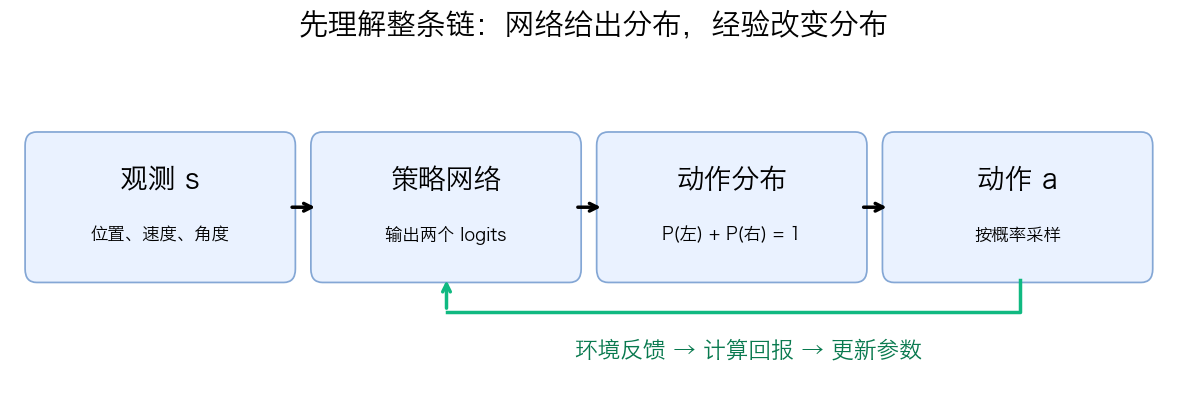

In [2]:
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.set(xlim=(0, 12), ylim=(0, 3)); ax.axis('off')
boxes = [(0.25, '观测 s', '位置、速度、角度'), (3.2, '策略网络', '输出两个 logits'),
         (6.15, '动作分布', 'P(左) + P(右) = 1'), (9.1, '动作 a', '按概率采样')]
for x, title, sub in boxes:
    ax.add_patch(FancyBboxPatch((x, 1.1), 2.55, 1.1, boxstyle='round,pad=0.12',
                               facecolor='#eaf2ff', edgecolor='#84a7d5'))
    ax.text(x+1.275, 1.82, title, ha='center', fontsize=16, weight='bold')
    ax.text(x+1.275, 1.36, sub, ha='center', fontsize=10)
    if x < 9:
        ax.annotate('', (x+2.91, 1.65), (x+2.6, 1.65), arrowprops={'arrowstyle':'->','lw':2})
ax.plot([10.4,10.4,4.48],[1.0,.72,.72],color='#10b981',lw=2)
ax.annotate('', (4.48, 1.03), (4.48, .72),
            arrowprops={'arrowstyle':'->','color':'#10b981','lw':2})
ax.text(7.6, 0.32, '环境反馈 → 计算回报 → 更新参数', ha='center', color='#08794e', fontsize=13)
ax.set_title('先理解整条链：网络给出分布，经验改变分布', fontsize=17)
showfig(fig, '01_policy_pipeline')

## 2. CartPole：网络到底看到了什么？

观测是四维向量：小车位置 $x$、小车速度 $\dot{x}$、杆角度 $\theta$、角速度 $\dot{\theta}$；动作 0/1 对应向左/向右施力。默认奖励是每走一步获得 1，包括导致终止的那一步，因此存活越久，回报越高。`CartPole-v1` 默认最多 500 步。[Gymnasium 环境定义](https://gymnasium.farama.org/environments/classic_control/cart_pole/)

**本章有一个明确的目标约定：** 最大化“自然失败或 500 步上限之前”的未折扣总回报，$\gamma=1$。我们把 500 步视为本次有限时长任务的边界，使用完整回合 Monte Carlo 回报，不在时间上限后自举。这不是“所有 truncated 都该当 terminated”的通用规则：若把它视为持续任务的外部截断，价值目标需要另行处理。

,观测项,动作前,向右施力后
0,x,0.027396,0.027273
1,x_dot,-0.006112,0.188478
2,theta,0.035860,0.036255
3,theta_dot,0.019737,-0.261420


reward = 1.0 | terminated = False | truncated = False
动作数 = 2 | 观测形状 = (4,) | 时间上限 = 500


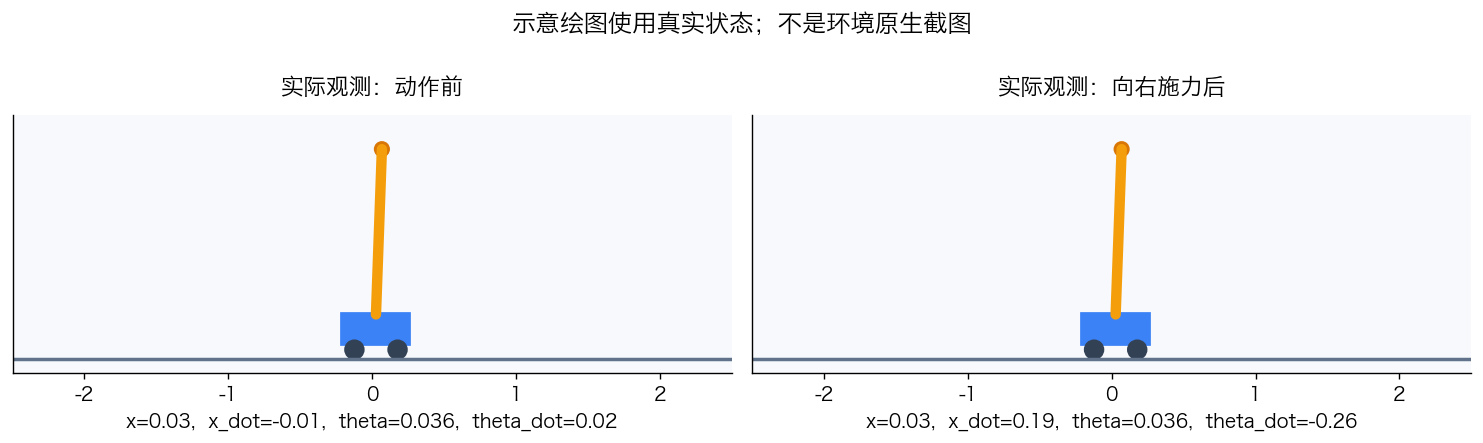

In [3]:
env = gym.make('CartPole-v1')
obs, info = env.reset(seed=42)
next_obs, reward, terminated, truncated, info = env.step(1)
display(pd.DataFrame({'观测项':['x','x_dot','theta','theta_dot'],
                      '动作前':obs, '向右施力后':next_obs}))
print('reward =', reward, '| terminated =', terminated, '| truncated =', truncated)
print('动作数 =', env.action_space.n, '| 观测形状 =', env.observation_space.shape,
      '| 时间上限 =', env.spec.max_episode_steps)
env.close()

def draw_cartpole(ax, observation, title):
    x, x_dot, angle, angle_dot = observation
    pivot = np.array([float(x), .31])
    tip = pivot + np.array([np.sin(angle), np.cos(angle)]) * 1.15
    ax.plot([-2.5, 2.5], [0, 0], color='#60738a', lw=2)
    ax.add_patch(Rectangle((x-.24, .1), .48, .22, color='#3b82f6'))
    for dx in (-.15, .15): ax.add_patch(Circle((x+dx, .065), .065, color='#334155'))
    ax.plot([pivot[0], tip[0]], [pivot[1], tip[1]], color='#f59e0b', lw=6, solid_capstyle='round')
    ax.add_patch(Circle(tuple(tip), .05, color='#d97706'))
    ax.set(xlim=(-2.5, 2.5), ylim=(-.1, 1.7), aspect='equal', title=title)
    ax.set_xlabel(f'x={x:.2f},  x_dot={x_dot:.2f},  theta={angle:.3f},  theta_dot={angle_dot:.2f}')
    ax.set_yticks([])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
draw_cartpole(axes[0], obs, '实际观测：动作前')
draw_cartpole(axes[1], next_obs, '实际观测：向右施力后')
fig.suptitle('示意绘图使用真实状态；不是环境原生截图', fontsize=14)
fig.tight_layout(); showfig(fig, '02_cartpole_state')

## 3. 从 logits 到动作：先把张量形状搞清楚

网络输出两个不受范围限制的实数 $z_0,z_1$，称为 logits。Softmax 把它们变成概率：

$$\pi_\theta(a=i\mid s)=\frac{e^{z_i}}{e^{z_0}+e^{z_1}}.$$

`Categorical(logits=...)` 会处理归一化；不要先 softmax 再把概率误传给 `logits=`。`sample()` 用于采样，`log_prob(action)` 用于取出已选动作的对数概率。[PyTorch 分布接口](https://docs.pytorch.org/docs/stable/distributions.html)

| 张量 | 单个观测 | 一批 N 个观测 |
| --- | --- | --- |
| observation | `(4,)` | `(N, 4)` |
| logits / probabilities | `(2,)` | `(N, 2)` |
| action | 标量整数 | `(N,)`，`torch.long` |
| log probability | 标量 | `(N,)` |

训练时采样不是 argmax。后者是另一种决策规则，会改变采集数据的策略。

In [4]:
class PolicyNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(4, 32), nn.Tanh(), nn.Linear(32, 2))

    def forward(self, observations):
        return self.net(observations)

    def distribution(self, observations):
        return Categorical(logits=self(observations))

torch.manual_seed(0)
demo_policy = PolicyNet()
demo_obs = torch.as_tensor(obs, dtype=torch.float32)
distribution = demo_policy.distribution(demo_obs)
action = distribution.sample()
display(pd.DataFrame({'动作':['左 / 0','右 / 1'],
                      'logit':demo_policy(demo_obs).detach().numpy(),
                      '概率':distribution.probs.detach().numpy()}))
print('采样动作:', action.item(), '| log_prob:', round(distribution.log_prob(action).item(), 4))
assert torch.allclose(distribution.probs.sum(), torch.tensor(1.0))
assert demo_policy.distribution(torch.zeros(5, 4)).log_prob(torch.zeros(5, dtype=torch.long)).shape == (5,)

,动作,logit,概率
0,左 / 0,-0.229209,0.444232
1,右 / 1,-0.005204,0.555768


采样动作: 0 | log_prob: -0.8114


## 4. 策略梯度：为什么不用对环境求导？

设一局轨迹为 $\tau=(s_0,a_0,r_0,\ldots,s_T)$，其中 $r_t$ 是在 $s_t$ 执行 $a_t$ 后得到的奖励。定义：

$$R(\tau)=\sum_{t=0}^{T-1}r_t,\qquad J(\theta)=\mathbb{E}_{\tau\sim\pi_\theta}[R(\tau)].$$

假设环境转移和初始分布不依赖策略参数，则

$$p_\theta(\tau)=\rho(s_0)\prod_t\pi_\theta(a_t\mid s_t)P(s_{t+1}\mid s_t,a_t).$$

应用 $\nabla p=p\nabla\log p$：

$$\begin{aligned}
\nabla_\theta J(\theta)
&=\int R(\tau)\nabla_\theta p_\theta(\tau)\,d\tau\\
&=\mathbb{E}_{\tau}\left[R(\tau)\nabla_\theta\log p_\theta(\tau)\right]\\
&=\mathbb{E}_{\tau}\left[\sum_t\nabla_\theta\log\pi_\theta(a_t\mid s_t)R(\tau)\right].
\end{aligned}$$

环境项不是“没有影响”，而是它们对 $\theta$ 的直接导数为零；环境依然决定轨迹和奖励。我们只须采样经验、对策略网络求导，不须让梯度穿过物理模拟器。

**直觉：** 当前采到的动作序列如果获得较高回报，就沿着提高这些动作对数概率的方向更新。一次样本可能幸运或倒霉，所以期望公式正确不意味着单次更新必然改善。

本节对应 [Spinning Up：最简单策略梯度推导](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html#deriving-the-simplest-policy-gradient)。

## 5. 将“最大化回报”写成可反向传播的 loss

采集 $M$ 个完整回合，每个动作分配权重 $w_{i,t}$，可构造：

$$L(\theta)=-\frac{1}{M}\sum_{i=1}^{M}\sum_t\log\pi_\theta(a_{i,t}\mid s_{i,t})\,w_{i,t}.$$

负号把梯度上升变为优化器的梯度下降。权重当作常量，不通过它反向传播。最简单版本令一局所有动作的权重都等于整局回报。

这里按**回合数 M**归一化，直接对应上面的轨迹平均。常见代码按总步数 N 取 `mean()`，在固定批次内只差正比例系数，但当平均回合长度变化时，梯度尺度也会改变。后文明确使用回合平均，并将所有版本的权重统一除以常数 100；这只对目标作固定正缩放，不做按批次去均值或标准化。

最容易误解的一点：这个 loss 是生成策略梯度的替代目标，数值不是环境表现的评分；不同批次的 loss 不宜当作回报曲线使用。当前策略采集的这批数据只做一次策略更新，再重新采样。[官方解释](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html#implementing-the-simplest-policy-gradient)

,更新前,正权重 +2 后,负权重 -2 后
左 / 0,0.5,0.401312,0.598688
右 / 1,0.5,0.598688,0.401312


正权重时 loss 对 logits 的梯度： [ 1. -1.]


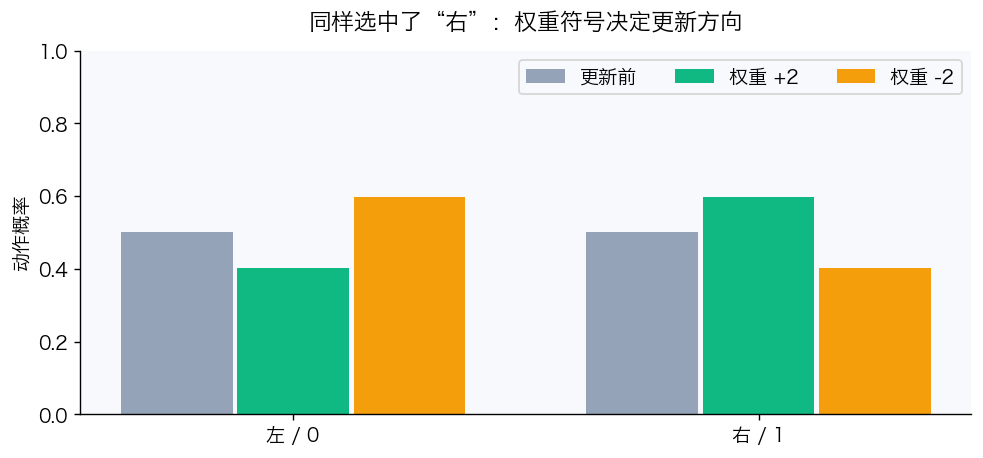

In [5]:
def policy_loss(policy, observations, actions, weights, episode_count):
    logp = policy.distribution(observations).log_prob(actions)
    assert logp.shape == weights.shape == actions.shape
    return -(logp * weights.detach()).sum() / episode_count

# 只看一个状态与两个动作，手工做一次 SGD。
def one_logit_update(weight):
    logits = torch.zeros(2, requires_grad=True)
    picked = torch.tensor(1, dtype=torch.long)
    before = logits.softmax(-1).detach().numpy()
    loss = -Categorical(logits=logits).log_prob(picked) * weight
    loss.backward()
    gradient = logits.grad.detach().clone()
    with torch.no_grad(): logits -= 0.2 * gradient
    return before, logits.softmax(-1).detach().numpy(), gradient.numpy()

before, positive, positive_grad = one_logit_update(2.0)
_, negative, negative_grad = one_logit_update(-2.0)
display(pd.DataFrame({'更新前':before, '正权重 +2 后':positive, '负权重 -2 后':negative},
                     index=['左 / 0','右 / 1']))
print('正权重时 loss 对 logits 的梯度：', positive_grad)
assert positive[1] > before[1] > negative[1]

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(2)
for offset, values, title, color in [(-.25,before,'更新前','#94a3b8'),
                                   (0,positive,'权重 +2','#10b981'),(.25,negative,'权重 -2','#f59e0b')]:
    ax.bar(x+offset, values, .24, label=title, color=color)
ax.set(xticks=x, xticklabels=['左 / 0','右 / 1'], ylim=(0,1), ylabel='动作概率',
       title='同样选中了“右”：权重符号决定更新方向')
ax.legend(ncol=3); fig.tight_layout(); showfig(fig, '03_single_update')

**手算核对：** 当 $p=(0.5,0.5)$、选择动作 1、权重为 2 时，$\partial L/\partial z=2(p-\mathrm{onehot}(1))=(1,-1)$。学习率 0.2 后，logits 变成 $(-0.2,0.2)$，向右概率约为 0.599，而不是 0.8。梯度先改参数，Softmax 再改变概率。

注意，所有回报都是正数不意味着所有动作概率一起增加：对数概率的梯度会在竞争动作之间重新分配概率。引入 baseline 后，动作还可以得到明确的正/负相对评价。

## 6. Reward-to-Go：现在的动作不必为过去的奖励负责

假设一局奖励依次是 `[1, 2, 3]`。整局回报给三个动作都分配 6；Reward-to-Go 给它们分配 `[6, 5, 3]`。

$$G_t=\sum_{k=t}^{T-1}r_k,\qquad w_t=G_t.$$

为什么可以去掉过去奖励？在选 $a_t$ 之前，历史奖励已确定，而条件于当前信息的动作得分函数满足 $\mathbb E[\nabla\log\pi(a_t\mid s_t)]=0$。过去奖励乘这个梯度项的期望为零，但样本中会带来额外噪声。

下面函数也支持折扣递推 $G_t=r_t+\gamma G_{t+1}$，用于手算练习。**主实验固定 gamma=1。** 如果改为优化从时刻 0 开始的严格折扣目标，推导中的外层时间权重也需要检查；不要只改一个 gamma 就声称目标完全相同。

,时刻,即时奖励,整局回报权重,Reward-to-Go
0,0,1.0,6,6.0
1,1,2.0,6,5.0
2,2,3.0,6,3.0


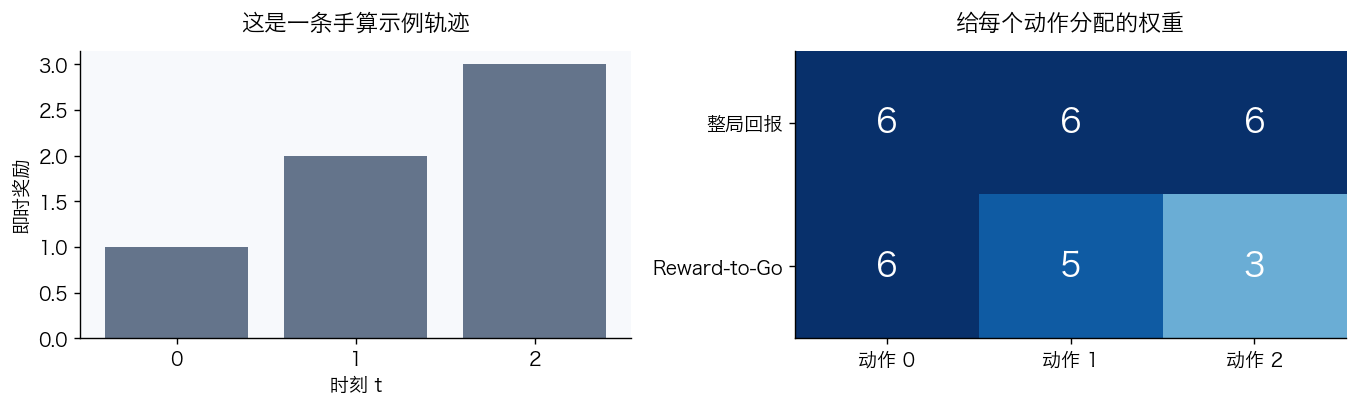

In [6]:
def reward_to_go(rewards, gamma=1.0):
    rewards = np.asarray(rewards, dtype=np.float32)
    values = np.empty_like(rewards)
    running = 0.0
    for t in range(len(rewards)-1, -1, -1):
        running = float(rewards[t]) + gamma * running
        values[t] = running
    return values

rewards = np.array([1, 2, 3], dtype=np.float32)
assert np.allclose(reward_to_go(rewards), [6, 5, 3])
assert np.allclose(reward_to_go(rewards, .9), [5.23, 4.7, 3])
assert reward_to_go([]).size == 0
display(pd.DataFrame({'时刻':[0,1,2], '即时奖励':rewards,
                      '整局回报权重':[6,6,6], 'Reward-to-Go':reward_to_go(rewards)}))
credit = np.array([[6,6,6], reward_to_go(rewards)])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].bar([0,1,2], rewards, color='#64748b')
axes[0].set(xticks=[0,1,2], xlabel='时刻 t', ylabel='即时奖励', title='这是一条手算示例轨迹')
axes[1].imshow(credit, cmap='Blues', vmin=0, vmax=6, aspect='auto')
axes[1].set(xticks=[0,1,2], xticklabels=['动作 0','动作 1','动作 2'],
            yticks=[0,1], yticklabels=['整局回报','Reward-to-Go'], title='给每个动作分配的权重')
for row in range(2):
    for col in range(3): axes[1].text(col,row,f'{credit[row,col]:.0f}',ha='center',va='center',color='white',fontsize=19)
fig.tight_layout(); showfig(fig, '04_credit_assignment')

## 7. Baseline：不是“得了多少”，而是“比预期好多少”

设基线只依赖状态、不依赖当前采样动作：

$$\mathbb E_{a\sim\pi_\theta(\cdot\mid s)}[\nabla_\theta\log\pi_\theta(a\mid s)b(s)]
=b(s)\nabla_\theta\sum_a\pi_\theta(a\mid s)=0.$$

因此可以用 $w_t=G_t-b(s_t)$。常见选择是价值网络 $V_\phi(s_t)$，用回报作为回归目标。单次 $G_t-V_\phi(s_t)$ 是带噪声的优势估计，不能把它直接当成精确 $A^\pi$。[Spinning Up：VPG](https://spinningup.openai.com/en/latest/algorithms/vpg.html)

**两个实现细节：**

- 策略更新时基线必须当常量，使用 `no_grad()` 或 `detach()`；否则会多出不是目标策略梯度的项。
- 本章先用“上一批训练好的价值网络”计算当前权重，再更新策略，最后拟合当前批次的价值目标。不会先把当前样本拟合进基线，再声称它与当前采样噪声独立。

基线不是越大越好，也不保证每次训练都更快。下面用一个可解析的单步玩具例子，隔离验证“期望不变、方差可以下降”；它不是 CartPole 性能证据。

,baseline,左分支梯度,右分支梯度,精确期望,精确方差
0,0.0,-0.5,1.5,0.5,1.0
1,2.0,0.5,0.5,0.5,0.0
2,8.0,3.5,-2.5,0.5,9.0


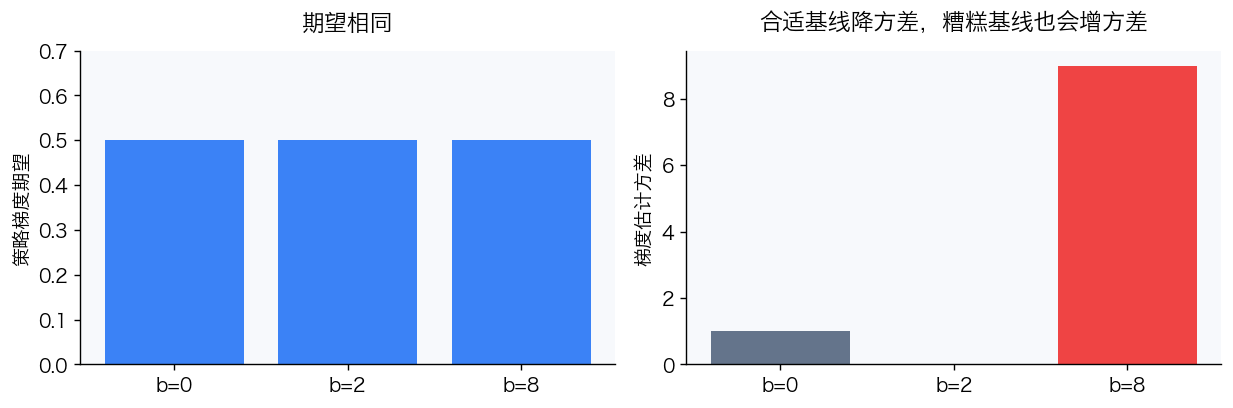

In [7]:
# 单步 Bernoulli 策略：p(右)=0.5，左奖励 1、右奖励 3。
# 对“右动作 logit”的 score = a-p；精确梯度为 p(1-p)*(3-1)=0.5。
toy_actions = np.array([0., 1.])
toy_rewards = np.array([1., 3.])
score = toy_actions - .5
rows = []
for baseline in [0., 2., 8.]:
    estimator = score * (toy_rewards - baseline)
    rows.append({'baseline':baseline, '左分支梯度':estimator[0], '右分支梯度':estimator[1],
                 '精确期望':estimator.mean(), '精确方差':estimator.var()})
toy_results = pd.DataFrame(rows)
display(toy_results)
assert np.allclose(toy_results['精确期望'], .5)
assert toy_results.loc[1,'精确方差'] == 0
assert toy_results.loc[2,'精确方差'] > toy_results.loc[0,'精确方差']
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].bar(['b=0','b=2','b=8'], toy_results['精确期望'], color='#3b82f6')
axes[0].set(title='期望相同', ylabel='策略梯度期望', ylim=(0,.7))
axes[1].bar(['b=0','b=2','b=8'], toy_results['精确方差'], color=['#64748b','#10b981','#ef4444'])
axes[1].set(title='合适基线降方差，糟糕基线也会增方差', ylabel='梯度估计方差')
fig.tight_layout(); showfig(fig, '05_baseline_variance')

## 8. 收集完整回合：数据必须来自当前策略

一批固定收集若干**完整回合**，采样期间策略不变；之后只更新一次策略，再丢弃这批策略训练数据。不要把 Q-learning 的 replay buffer 直接搬到这里。

采样时不保存计算图，更新时用当前网络重新计算每个观测的 log probability。因为整批采样期间参数没有变，这些概率对应的仍是采样策略。

为了让训练、评估互不干扰，下面用独立的 `torch.Generator`，通过 `torch.multinomial` 采样同一个 Categorical 概率分布。它与前面 `distribution.sample()` 的采样规则相同，只是随机数流单独管理。

In [8]:
@torch.no_grad()
def sample_action(policy, observation, generator, greedy=False):
    observation = torch.as_tensor(observation, dtype=torch.float32)
    probabilities = policy.distribution(observation).probs
    if greedy:
        return int(probabilities.argmax().item())
    return int(torch.multinomial(probabilities, 1, generator=generator).item())

def collect_episodes(env, policy, episode_count, episode_seed, generator):
    observations, actions, full_returns, rtg = [], [], [], []
    returns, lengths = [], []
    for i in range(episode_count):
        state, _ = env.reset(seed=episode_seed+i)
        episode_observations, episode_actions, rewards = [], [], []
        while True:
            action = sample_action(policy, state, generator)
            next_state, reward, terminated, truncated, _ = env.step(action)
            episode_observations.append(state.copy())
            episode_actions.append(action)
            rewards.append(reward)
            state = next_state
            if terminated or truncated:
                break
        total = float(sum(rewards))
        observations.extend(episode_observations)
        actions.extend(episode_actions)
        full_returns.extend([total]*len(rewards))
        rtg.extend(reward_to_go(rewards))
        returns.append(total); lengths.append(len(rewards))
    return dict(obs=torch.tensor(np.asarray(observations), dtype=torch.float32),
                actions=torch.tensor(actions, dtype=torch.long),
                episode_returns=torch.tensor(full_returns, dtype=torch.float32),
                rtg=torch.tensor(rtg, dtype=torch.float32),
                returns=np.array(returns), lengths=np.array(lengths),
                episode_count=episode_count)

test_env = gym.make('CartPole-v1')
batch = collect_episodes(test_env, demo_policy, 3, 9000, torch.Generator().manual_seed(7))
test_env.close()
print({k:tuple(v.shape) for k,v in batch.items() if isinstance(v,torch.Tensor)})
print('这批回合长度:', batch['lengths'].tolist())
assert batch['obs'].shape[0] == int(batch['lengths'].sum())
assert batch['actions'].dtype == torch.long
assert batch['rtg'].requires_grad is False

{'obs': (42, 4), 'actions': (42,), 'episode_returns': (42,), 'rtg': (42,)}
这批回合长度: [14, 15, 13]


## 9. 三种权重，一个训练框架

策略网络、优化器、学习率、种子与每批回合数保持一致，仅改变权重定义；baseline 版本额外训练一个价值网络。训练中的总交互步数可能不同——活得久的策略每局走得更多，所以后文横轴用环境步数，不能只凭 epoch 数声称样本效率更高。

价值网络预测的是 `return / 100`；三种策略权重也统一缩放到同样单位。先计算固定权重，再做一次策略梯度更新；价值网络随后可对监督回归目标训练多步，这不等于把同一批数据对策略重复更新。

In [9]:
class ValueNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(4, 32), nn.Tanh(), nn.Linear(32, 1))
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def forward(self, observations):
        return self.net(observations).squeeze(-1)

RETURN_SCALE = 100.0

def update_once(policy, value, policy_optimizer, value_optimizer, batch, mode,
                value_steps=30):
    with torch.no_grad():
        if mode == 'episode':
            weights = batch['episode_returns'] / RETURN_SCALE
        elif mode == 'rtg':
            weights = batch['rtg'] / RETURN_SCALE
        elif mode == 'baseline':
            weights = batch['rtg'] / RETURN_SCALE - value(batch['obs'])
        else:
            raise ValueError(mode)
    policy_optimizer.zero_grad(set_to_none=True)
    loss = policy_loss(policy, batch['obs'], batch['actions'], weights, batch['episode_count'])
    loss.backward()
    grad_norm = torch.sqrt(sum(p.grad.square().sum() for p in policy.parameters()))
    if not torch.isfinite(loss) or not torch.isfinite(grad_norm):
        raise FloatingPointError('策略梯度出现非有限值，请检查权重、学习率与形状。')
    policy_optimizer.step()  # 当前批次只更新一次策略
    value_loss = float('nan')
    if mode == 'baseline':
        targets = batch['rtg'] / RETURN_SCALE
        for _ in range(value_steps):
            value_optimizer.zero_grad(set_to_none=True)
            value_error = (value(batch['obs']) - targets).square().mean()
            value_error.backward()
            value_optimizer.step()
        value_loss = value_error.item()
    with torch.no_grad():
        entropy = policy.distribution(batch['obs']).entropy().mean().item()
    return dict(loss=loss.item(), grad_norm=grad_norm.item(),
                entropy=entropy, weight_std=weights.std(unbiased=False).item(),
                value_loss=value_loss)

def train(mode, seed, epochs=60, episodes_per_batch=12, lr=0.01):
    torch.manual_seed(seed)
    policy, value = PolicyNet(), ValueNet()  # 各版本创建相同结构，保证初始策略一致
    initial_policy = copy.deepcopy(policy)
    policy_optimizer = torch.optim.Adam(policy.parameters(), lr=lr)
    value_optimizer = torch.optim.Adam(value.parameters(), lr=0.01)
    generator = torch.Generator().manual_seed(seed+12345)
    env = gym.make('CartPole-v1')
    history = []; steps = 0
    try:
        for epoch in range(epochs):
            batch = collect_episodes(env, policy, episodes_per_batch,
                                     seed*100000+epoch*episodes_per_batch, generator)
            steps += len(batch['actions'])
            metrics = update_once(policy, value, policy_optimizer, value_optimizer, batch, mode)
            history.append(dict(mode=mode, seed=seed, epoch=epoch+1, steps=steps,
                                train_return=batch['returns'].mean(), **metrics))
    finally:
        env.close()
    return policy, initial_policy, pd.DataFrame(history)

### 9.1 更新逻辑的检查，不只检查代码能跑

下面断言确保策略参数发生变化；基线权重不会把策略 loss 的梯度传给价值网络；训练张量的形状一致。`detach()` 不代表冻结策略，它只阻止通过权重分支求导。

In [10]:
torch.manual_seed(123)
check_policy, check_value = PolicyNet(), ValueNet()
check_optimizer = torch.optim.SGD(check_policy.parameters(), lr=.01)
with torch.no_grad():
    check_weights = batch['rtg']/RETURN_SCALE - check_value(batch['obs'])
old_parameters = torch.cat([p.detach().flatten() for p in check_policy.parameters()]).clone()
check_optimizer.zero_grad(set_to_none=True)
check_loss = policy_loss(check_policy, batch['obs'], batch['actions'], check_weights, 3)
check_loss.backward()
assert all(p.grad is None for p in check_value.parameters())
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in check_policy.parameters())
check_optimizer.step()
new_parameters = torch.cat([p.detach().flatten() for p in check_policy.parameters()])
assert not torch.equal(old_parameters, new_parameters)
print('通过：概率归一化、张量形状、RTG 手算、单步方向、基线期望、梯度隔离、参数更新。')

通过：概率归一化、张量形状、RTG 手算、单步方向、基线期望、梯度隔离、参数更新。


## 10. 运行预先固定的多种子实验

这里比较三个教学实现，不是算法排行榜。只使用 3 个训练种子，足以暴露部分波动，但不足以证明普遍优劣；超参数没有为每个算法单独做完整搜索。固定 CPU 和种子有助于复现，但不保证不同平台、依赖版本逐位一致。

本单元会真正训练，不读取预先挑好的成功曲线，也不在效果不佳时自动重抽种子。保存最终策略用于评估，不挑“最好一轮”替换结论。

In [11]:
SEEDS = [0, 1, 2]
MODES = ['episode', 'rtg', 'baseline']
EPOCHS = 60
EPISODES_PER_BATCH = 12
LEARNING_RATE = .01
policies, initial_policies, histories = {}, {}, []
started = time.perf_counter()
for mode in MODES:
    for seed in SEEDS:
        policy, initial, history = train(mode, seed, EPOCHS, EPISODES_PER_BATCH, LEARNING_RATE)
        policies[(mode, seed)] = policy
        initial_policies[(mode, seed)] = initial
        histories.append(history)
        print(f'{NAMES[mode]:18s} seed={seed} | steps={int(history.steps.iloc[-1]):6d}'
              f' | 最近 10 批平均回报={history.train_return.tail(10).mean():6.1f}', flush=True)
training = pd.concat(histories, ignore_index=True)
training.to_csv(ARTIFACTS/'training.csv', index=False)
config = dict(seeds=SEEDS, modes=MODES, epochs=EPOCHS, episodes_per_batch=EPISODES_PER_BATCH,
              policy_lr=LEARNING_RATE, value_lr=.01, value_steps=30, gamma=1.0,
              return_scale=RETURN_SCALE, max_episode_steps=500, versions=versions)
(ARTIFACTS/'run_config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
print(f'训练耗时：{time.perf_counter()-started:.1f} 秒')

整局回报               seed=0 | steps= 58416 | 最近 10 批平均回报= 170.6


整局回报               seed=1 | steps= 63709 | 最近 10 批平均回报= 174.3


整局回报               seed=2 | steps= 72762 | 最近 10 批平均回报= 206.2


Reward-to-Go       seed=0 | steps=155934 | 最近 10 批平均回报= 331.1


Reward-to-Go       seed=1 | steps=180770 | 最近 10 批平均回报= 476.2


Reward-to-Go       seed=2 | steps=162119 | 最近 10 批平均回报= 476.5


RTG + 价值基线         seed=0 | steps=195224 | 最近 10 批平均回报= 464.8


RTG + 价值基线         seed=1 | steps=199437 | 最近 10 批平均回报= 498.9


RTG + 价值基线         seed=2 | steps=198875 | 最近 10 批平均回报= 496.4


训练耗时：58.4 秒


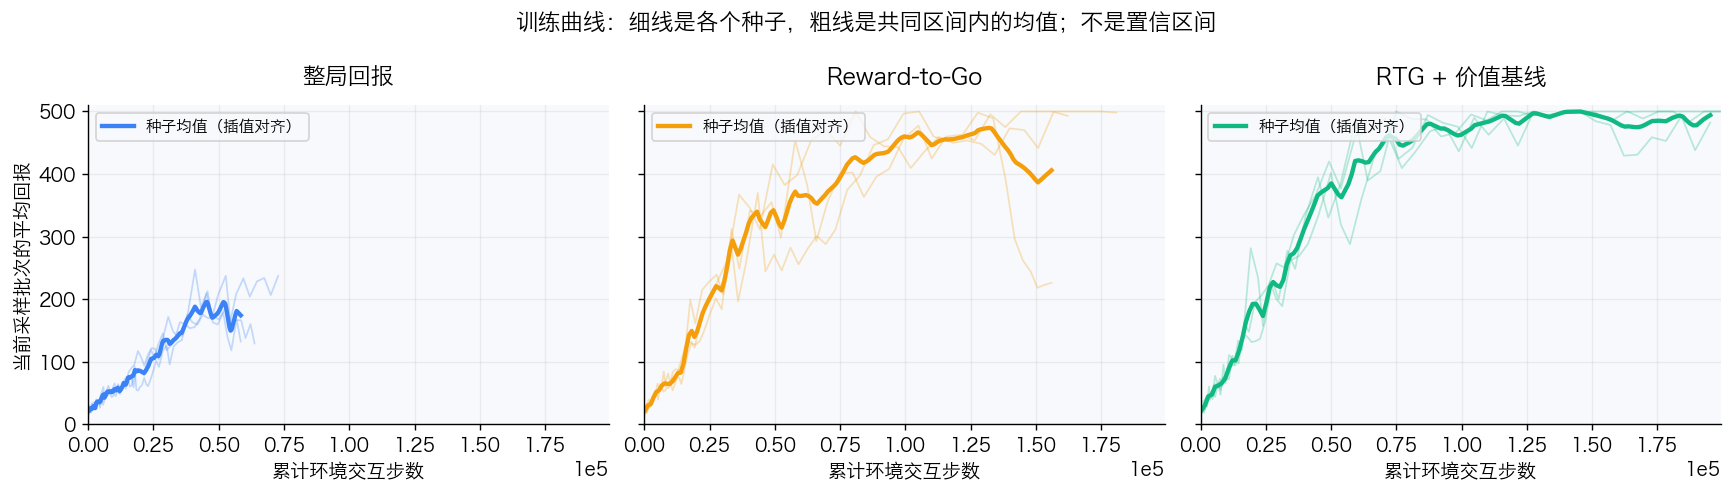

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, mode in zip(axes, MODES):
    subsets = [training[(training['mode']==mode) & (training.seed==s)] for s in SEEDS]
    for h in subsets:
        ax.plot(h.steps, h.train_return, color=COLORS[mode], alpha=.28, lw=1)
    # 仅在三个种子均有记录的交互步数区间求均值，不向末端外推。
    left = max(h.steps.iloc[0] for h in subsets)
    right = min(h.steps.iloc[-1] for h in subsets)
    grid = np.linspace(left, right, 150)
    aligned = np.stack([np.interp(grid, h.steps, h.train_return) for h in subsets])
    ax.plot(grid, aligned.mean(0), color=COLORS[mode], lw=2.5, label='种子均值（插值对齐）')
    ax.set(title=NAMES[mode], xlabel='累计环境交互步数', ylim=(0,510),
           xlim=(0, training.steps.max()))
    ax.ticklabel_format(axis='x', style='sci', scilimits=(0,0))
    ax.grid(alpha=.2); ax.legend(fontsize=9, loc='upper left')
axes[0].set_ylabel('当前采样批次的平均回报')
fig.suptitle('训练曲线：细线是各个种子，粗线是共同区间内的均值；不是置信区间', fontsize=13)
fig.tight_layout(); showfig(fig, '06_training_curves')

### 如何读这张图

训练回报属于更新**前**采样策略；网络更新后是否更好，需要新回合评估。粗线只是将各随机种子的记录按交互步数插值后取平均，不是新采集的观测，也不是统计置信区间。越靠后的可比较区间可能越短。

不要预设 baseline 必须赢。价值估计误差、学习率、采样数量都会影响表现；上面玩具例子证明的是某个基线可以降方差，并未证明这里的学习基线总是更好。

## 11. 独立评估：随机策略和贪心策略分开报告

训练完成后使用另一组环境种子，并单独管理动作随机数。对每个训练种子的最终策略评估 30 个回合，不更新参数。

主指标评估**随机采样策略**，因为它才是训练目标；额外报告 argmax 策略，但不偷偷用它替换原策略。达到 500 步的比例只是本环境的时间上限达成率，不代表在所有初始条件下都稳定成功。

In [13]:
@torch.no_grad()
def evaluate(policy, count=30, greedy=False, seed_base=1000000):
    env = gym.make('CartPole-v1')
    rows = []
    try:
        for episode in range(count):
            state, _ = env.reset(seed=seed_base+episode)
            generator = torch.Generator().manual_seed(seed_base+5000+episode)
            total = 0.0; length = 0
            while True:
                action = sample_action(policy, state, generator, greedy)
                state, reward, terminated, truncated, _ = env.step(action)
                total += reward; length += 1
                if terminated or truncated: break
            rows.append(dict(eval_episode=episode, return_=total, length=length,
                             reached_cap=bool(truncated and not terminated)))
    finally: env.close()
    return pd.DataFrame(rows)

eval_parts = []
for mode in MODES:
    for seed in SEEDS:
        for greedy in [False, True]:
            result = evaluate(policies[(mode,seed)], greedy=greedy)
            result['mode']=mode; result['train_seed']=seed
            result['decision']='argmax' if greedy else 'sample'
            eval_parts.append(result)
evaluation = pd.concat(eval_parts, ignore_index=True)
evaluation.to_csv(ARTIFACTS/'evaluation.csv', index=False)
per_seed = evaluation.groupby(['mode','decision','train_seed']).agg(
    mean_return=('return_','mean'), std_episodes=('return_','std'), cap_rate=('reached_cap','mean')).reset_index()
summary = per_seed.groupby(['mode','decision']).agg(
    mean_return=('mean_return','mean'), std_across_train_seeds=('mean_return','std'),
    cap_rate=('cap_rate','mean')).reset_index()
display(summary.round(3))
print('std_across_train_seeds 是 3 个“每个训练种子的平均回报”的样本标准差，不是置信区间。')

random_policy_evaluation = evaluate(initial_policies[('rtg',0)])
print('初始化随机网络（seed=0，未训练）采样评估平均回报：',random_policy_evaluation['return_'].mean())

,mode,decision,mean_return,std_across_train_seeds,cap_rate
0,baseline,argmax,498.933,1.848,0.967
1,baseline,sample,492.022,9.694,0.956
2,episode,argmax,332.833,121.645,0.178
3,episode,sample,159.900,47.158,0.000
4,rtg,argmax,394.956,150.877,0.522
5,rtg,sample,384.222,145.299,0.456


std_across_train_seeds 是 3 个“每个训练种子的平均回报”的样本标准差，不是置信区间。
初始化随机网络（seed=0，未训练）采样评估平均回报： 19.233333333333334


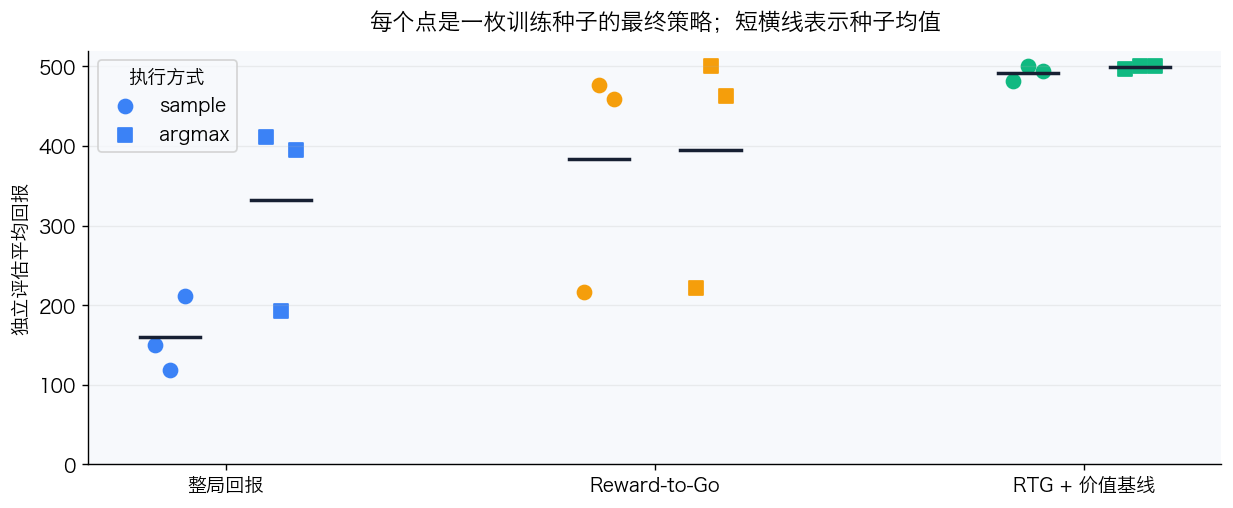

### 本次运行记录

- **整局回报**：最终采样策略平均回报 159.9；训练种子间标准差 47.2；时间上限达成率 0.0%。
- **Reward-to-Go**：最终采样策略平均回报 384.2；训练种子间标准差 145.3；时间上限达成率 45.6%。
- **RTG + 价值基线**：最终采样策略平均回报 492.0；训练种子间标准差 9.7；时间上限达成率 95.6%。

这些结果只支持当前环境、预算与配置下的比较。三种子实验不是泛化保证；未达上限、波动或基线落后同样是应保留的结果。

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for i,mode in enumerate(MODES):
    for offset,decision,marker in [(-.13,'sample','o'),(.13,'argmax','s')]:
        rows = per_seed[(per_seed['mode']==mode) & (per_seed.decision==decision)]
        jitter = np.linspace(-.035,.035,len(rows))
        ax.scatter(i+offset+jitter,rows.mean_return,color=COLORS[mode],marker=marker,s=65,
                   label=decision if i==0 else None)
        ax.plot([i+offset-.07,i+offset+.07],[rows.mean_return.mean()]*2,color='#172033',lw=2)
ax.set(xticks=range(3),xticklabels=[NAMES[m] for m in MODES],ylabel='独立评估平均回报',ylim=(0,520),
       title='每个点是一枚训练种子的最终策略；短横线表示种子均值')
ax.legend(title='执行方式'); ax.grid(axis='y',alpha=.2)
fig.tight_layout(); showfig(fig,'07_evaluation')

# 结果解释由实际记录生成，不写死“某算法一定成功”。
lines = ['### 本次运行记录', '']
for mode in MODES:
    row=summary[(summary['mode']==mode)&(summary.decision=='sample')].iloc[0]
    lines.append(f'- **{NAMES[mode]}**：最终采样策略平均回报 {row.mean_return:.1f}；'
                 f'训练种子间标准差 {row.std_across_train_seeds:.1f}；时间上限达成率 {row.cap_rate:.1%}。')
lines += ['', '这些结果只支持当前环境、预算与配置下的比较。三种子实验不是泛化保证；'
          '未达上限、波动或基线落后同样是应保留的结果。']
display(Markdown('\n'.join(lines)))

## 12. 网络究竟改了什么？查看同一组观测的动作概率

固定杆的角度和角速度，让小车位置与速度为 0，观察向右动作的概率。这是四维策略的二维切片，部分组合不一定经常在真实轨迹里出现，因此不能拿它代替环境评估。

展示预先指定的 `rtg, seed=0`，不是根据结果挑出的最好模型。随机策略不一定要把概率压到 0 或 1；决策还与未画出的两个观测分量有关。

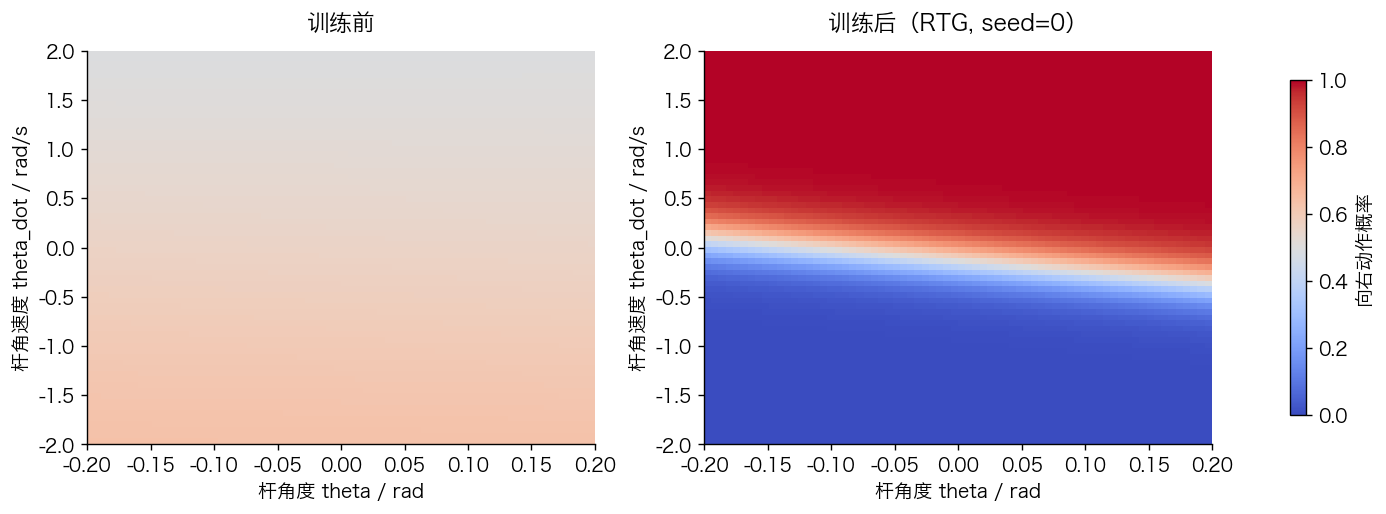

In [15]:
angles = np.linspace(-.20,.20,70)
angular_velocities = np.linspace(-2.0,2.0,70)
theta_grid, velocity_grid = np.meshgrid(angles,angular_velocities)
probe = np.zeros((theta_grid.size,4),dtype=np.float32)
probe[:,2]=theta_grid.ravel(); probe[:,3]=velocity_grid.ravel()
fig,axes = plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for ax,policy,title in zip(axes,[initial_policies[('rtg',0)],policies[('rtg',0)]],['训练前','训练后（RTG, seed=0）']):
    with torch.no_grad(): probs = policy.distribution(torch.tensor(probe)).probs[:,1].numpy().reshape(theta_grid.shape)
    im=ax.imshow(probs,origin='lower',extent=[angles.min(),angles.max(),angular_velocities.min(),angular_velocities.max()],
                 aspect='auto',vmin=0,vmax=1,cmap='coolwarm')
    ax.set(title=title,xlabel='杆角度 theta / rad',ylabel='杆角速度 theta_dot / rad/s')
fig.colorbar(im,ax=list(axes),label='向右动作概率',shrink=.85)
showfig(fig,'08_policy_slice')

## 13. 让最终策略实际走一遍

仍使用固定的 RTG、seed=0 模型和新的环境种子。下面的轨迹与小车快照都来自真实环境交互。快照是根据观测绘制的示意图，不是挑选、拼接出来的成功片段。

本条轨迹：191 步，回报 191，terminated=True, truncated=False


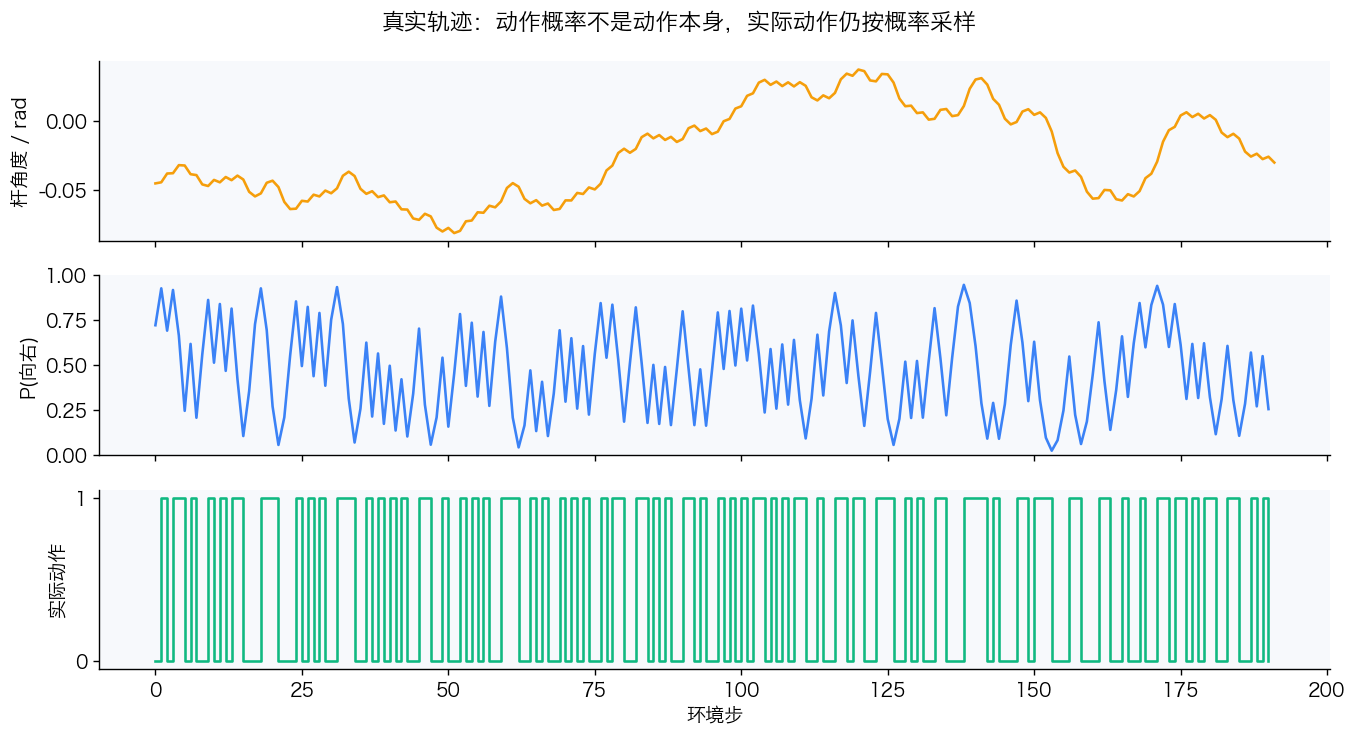

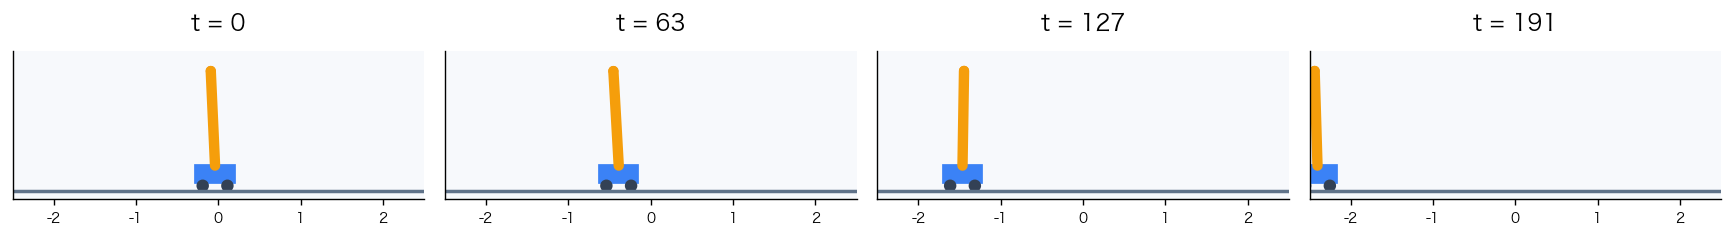

In [16]:
@torch.no_grad()
def rollout(policy, seed=20260927):
    env=gym.make('CartPole-v1')
    observation,_=env.reset(seed=seed)
    generator=torch.Generator().manual_seed(seed+1)
    states=[observation.copy()]; actions=[]; probabilities=[]; rewards=[]
    try:
        while True:
            probabilities.append(policy.distribution(torch.tensor(observation,dtype=torch.float32)).probs.numpy())
            action=sample_action(policy,observation,generator)
            observation,reward,terminated,truncated,_=env.step(action)
            states.append(observation.copy()); actions.append(action); rewards.append(reward)
            if terminated or truncated: break
    finally: env.close()
    return np.array(states),np.array(actions),np.array(probabilities),np.array(rewards),terminated,truncated

states, actions, probabilities, rewards, terminated, truncated = rollout(policies[('rtg',0)])
print(f'本条轨迹：{len(actions)} 步，回报 {rewards.sum():.0f}，terminated={terminated}, truncated={truncated}')
np.savez(ARTIFACTS/'rollout.npz',states=states,actions=actions,probabilities=probabilities,rewards=rewards)
fig,axes=plt.subplots(3,1,figsize=(11,6),sharex=True)
axes[0].plot(states[:,2],color='#f59e0b'); axes[0].set_ylabel('杆角度 / rad')
axes[1].plot(probabilities[:,1],color='#3b82f6'); axes[1].set(ylabel='P(向右)',ylim=(0,1))
axes[2].step(np.arange(len(actions)),actions,where='post',color='#10b981'); axes[2].set(yticks=[0,1],ylabel='实际动作',xlabel='环境步')
fig.suptitle('真实轨迹：动作概率不是动作本身，实际动作仍按概率采样')
fig.tight_layout(); showfig(fig,'09_rollout')
fig,axes=plt.subplots(1,4,figsize=(14,3))
for ax,index in zip(axes,np.linspace(0,len(states)-1,4,dtype=int)):
    draw_cartpole(ax,states[index],f't = {index}')
    ax.set_xlabel(''); ax.tick_params(labelsize=8)
fig.tight_layout(); showfig(fig,'10_cartpole_snapshots')

## 14. 容易踩的坑，以及本章与官方实现的差异

| 容易出错的位置 | 正确检查方式 |
| --- | --- |
| 把 softmax 后概率再传给 `logits=` | 网络直接输出 logits；或明确用 `probs=` |
| action 不是 long，或 logp/weights 变成 `(N,1)` 与 `(N,)` | 检查 dtype 与形状，避免广播成 `(N,N)` |
| 对同一批旧策略样本反复更新策略 | 本章每批只更新一次；PPO 是后续另一个完整算法 |
| 只看 loss 是否下降 | 独立环境回报才是核心；还要看种子差异 |
| value 和 policy 共享计算图，权重不 detach | 将优势权重视为常数，分别更新 |
| 训练时用 argmax，却用随机策略公式解释采样 | 按当前分布采样，明确区分两种评估 |
| 用训练中的最好一局宣布收敛 | 报告最终模型、多回合、多种子 |
| 一律把时间截断置零或一律自举 | 先明确有限任务边界还是持续任务截断 |

与 Spinning Up 的关系：

- 理论入口是 Part 3 的简单策略梯度与 Reward-to-Go；本章重新组织为独立可运行的中文学习笔记。
- 使用 Gymnasium 五返回值接口，而不是旧 Gym 的 `done`；使用 `CartPole-v1`、CPU、小网络和明确的有限时长目标。
- 每批固定完整回合数，按回合平均；官方入门示例按收集步数阈值组批，并按步取均值。两者归一化、批次规模不完全一致。
- 本章加了一个 Monte Carlo 价值基线版本，但**不是完整官方 VPG**：没有 GAE、MPI、多环境并行或 epoch 边界自举。完整 VPG 的这些实现细节需要下一阶段单独学习。[官方 VPG 文档](https://spinningup.openai.com/en/latest/algorithms/vpg.html)
- 除以 100 是三个版本共用的固定数值缩放；没有优势标准化、熵奖励、梯度裁剪或 checkpoint 挑选。它们可以是后续实验，但不应偷偷加入以美化结果。

## 15. 动手练习

1. 把第 5 节手算权重改为 0，检查概率是否保持不变；再把初始 logits 改成 `[2, -1]`，验证不是每次都从 0.5 开始。
2. 用 `[0, 0, 1]` 和 `[1, -1, 2]` 验证 RTG，解释为什么即时奖励不是策略训练权重。
3. 将每批回合数从 12 增至 24。保持总环境交互预算尽量接近，比较曲线波动，而不是只比较 epoch 数。
4. 在单步玩具例子中扫描基线 b，画梯度方差随 b 的变化。最小方差基线是否总等于平均奖励？改变动作概率后再试。
5. 在主实验加入更多预先固定种子，报告所有结果。不要看到失败后删除那个种子。

<details><summary>自测提示：我是否真的理解了？</summary>

如果能说明“策略输出分布”“动作采样不求导，但已选动作的 log probability 可以求导”“回报只作为权重”“基线的合法性来自条件期望为零”“旧样本不能无条件反复用于策略更新”，就抓住了本章核心。网络更大不自动解决数据与估计问题。

</details>

## 16. 小结与下一步

这次不再给每个动作维护一个表格项，而是通过完整轨迹改变动作分布。整局回报先建立最小闭环；Reward-to-Go 去掉过去奖励的无效贡献；价值基线把绝对回报变成相对评价。最终效果必须由真实评估验证。

下一步可将本章的价值基线发展为优势估计，学习 TD 残差与 GAE，再对照完整 VPG；之后再进入 PPO 的概率比率与受限更新。

### 官方阅读索引

1. [OpenAI Spinning Up：核心概念](https://spinningup.openai.com/en/latest/spinningup/rl_intro.html)——状态、策略、轨迹、回报。
2. [OpenAI Spinning Up：算法分类](https://spinningup.openai.com/en/latest/spinningup/rl_intro2.html)——策略优化与价值学习的关系。
3. [OpenAI Spinning Up：策略优化入门](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html)——本章理论主线和入门代码入口。
4. [OpenAI Spinning Up：VPG](https://spinningup.openai.com/en/latest/algorithms/vpg.html)——优势形式与完整实现边界。
5. [Gymnasium：CartPole](https://gymnasium.farama.org/environments/classic_control/cart_pole/)——环境、动作、奖励和时间上限。
6. [PyTorch：概率分布](https://docs.pytorch.org/docs/stable/distributions.html)——Categorical、采样与 log probability。

文档核对日期：2026-09-27。运行版本由第 0 节自动打印并写入实验配置。文中的示意图与实验图均由本笔记代码生成。